In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
import pandas as pd

df = pd.read_csv("sales_data_1200_rows.csv")

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,Order_ID,Order_Date,Product_Name,Category,Region,Quantity,Revenue,Cost,Customer_ID
0,ORD0224,2024-01-01,Zara Jacket,Fashion,East,9,45000,27000,CUST156
1,ORD0210,2024-01-02,Raymond Shirt,Fashion,East,3,6000,3300,CUST267
2,ORD0818,2024-01-02,Raymond Shirt,Fashion,North,6,12000,6600,CUST315
3,ORD0433,2024-01-02,Forever 21 Top,Fashion,South,2,3000,1600,CUST337
4,ORD0391,2024-01-03,Apple Watch,Electronics,South,4,160000,128000,CUST210


In [9]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (1200, 9)

Column Names:
['Order_ID', 'Order_Date', 'Product_Name', 'Category', 'Region', 'Quantity', 'Revenue', 'Cost', 'Customer_ID']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Order_ID      1200 non-null   object
 1   Order_Date    1200 non-null   object
 2   Product_Name  1200 non-null   object
 3   Category      1200 non-null   object
 4   Region        1200 non-null   object
 5   Quantity      1200 non-null   int64 
 6   Revenue       1200 non-null   int64 
 7   Cost          1200 non-null   int64 
 8   Customer_ID   1200 non-null   object
dtypes: int64(3), object(6)
memory usage: 84.5+ KB


In [10]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Order_ID        0
Order_Date      0
Product_Name    0
Category        0
Region          0
Quantity        0
Revenue         0
Cost            0
Customer_ID     0
dtype: int64

Duplicate Rows:
0


In [11]:
df.describe()

,Quantity,Revenue,Cost
count,1200.000000,1.200000e+03,1.200000e+03
mean,3.005000,9.423325e+04,7.047850e+04
std,2.039225,1.622346e+05,1.279418e+05
min,1.000000,1.500000e+03,8.000000e+02
25%,1.000000,1.000000e+04,6.600000e+03
50%,2.000000,3.500000e+04,2.325000e+04
75%,4.000000,1.050000e+05,7.625000e+04
max,10.000000,2.400000e+06,2.000000e+06


In [12]:
numeric_columns = df.select_dtypes(include=['number']).columns

print("Numeric Columns:")
print(numeric_columns.tolist())

Numeric Columns:
['Quantity', 'Revenue', 'Cost']


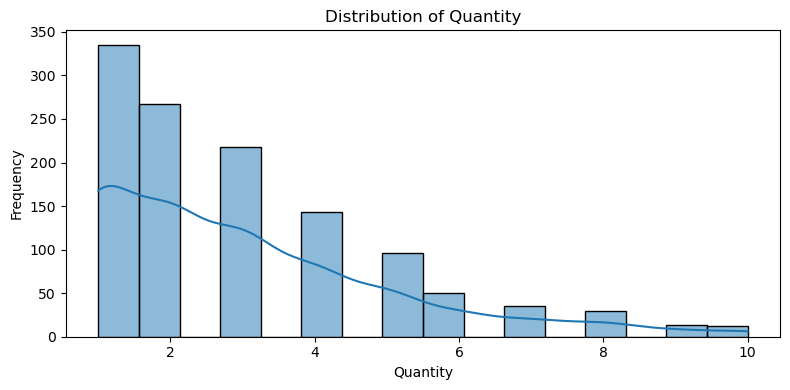

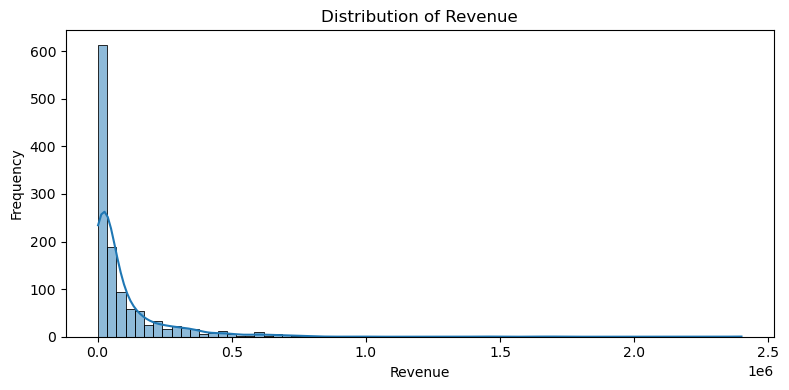

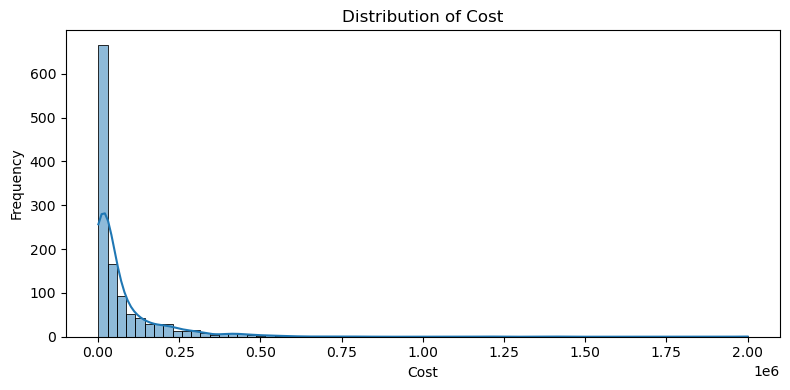

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in numeric_columns:
    plt.figure(figsize=(8, 4))

    sns.histplot(df[col].dropna(), kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

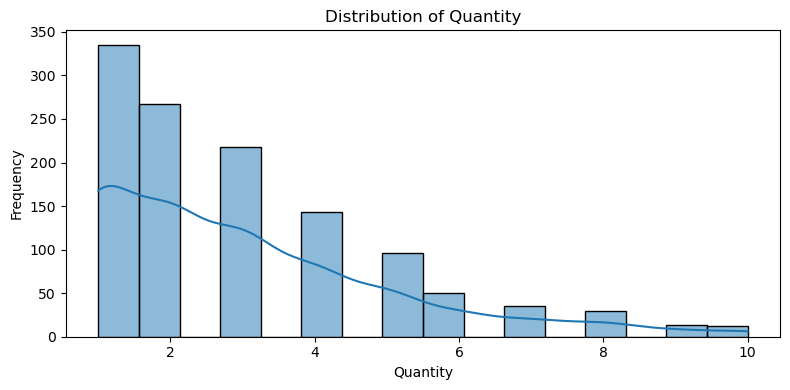

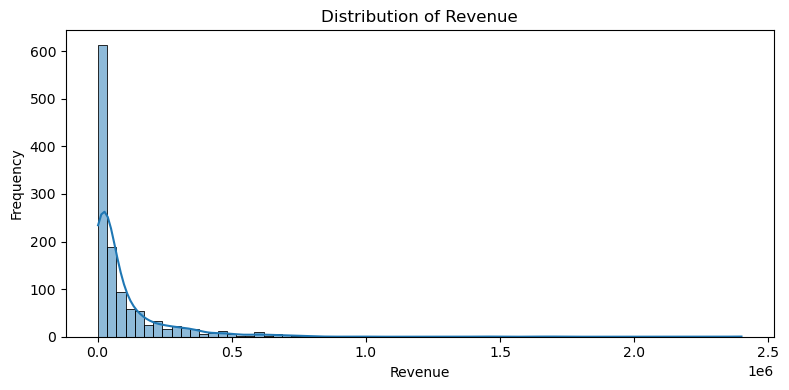

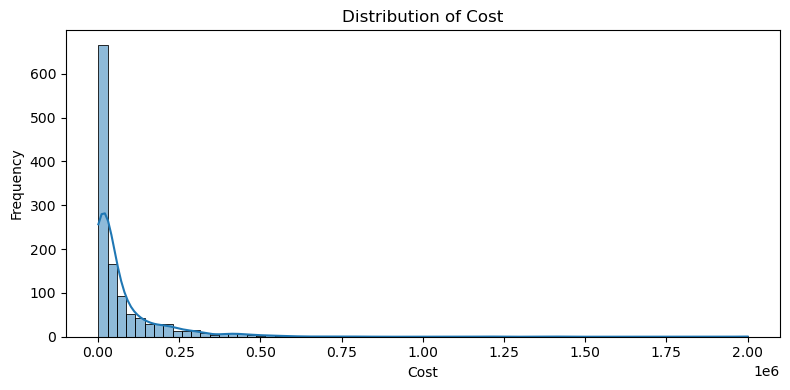

In [14]:
import os

os.makedirs("charts", exist_ok=True)

for col in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col].dropna(), kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.savefig(f"charts/{col}_distribution.png")
    plt.show()
    plt.close()

In [15]:
correlation = df.select_dtypes(include=['number']).corr()

print(correlation)

          Quantity   Revenue      Cost
Quantity  1.000000  0.410465  0.397418
Revenue   0.410465  1.000000  0.996089
Cost      0.397418  0.996089  1.000000


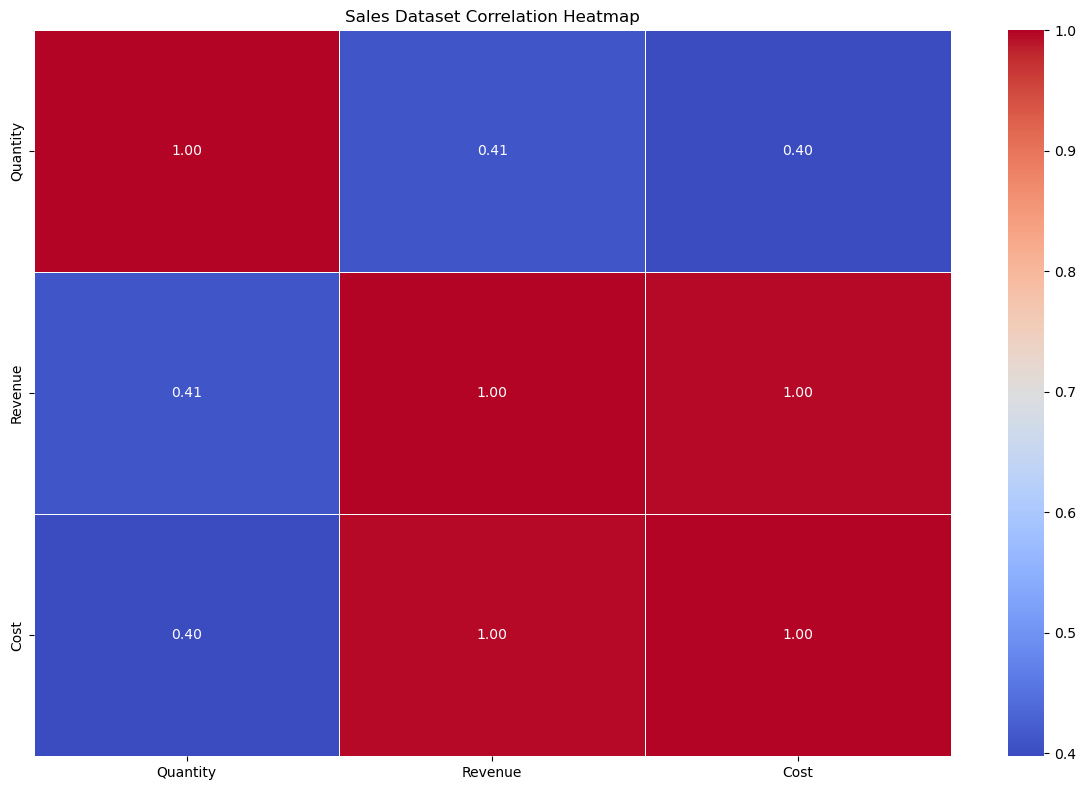

In [16]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Sales Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

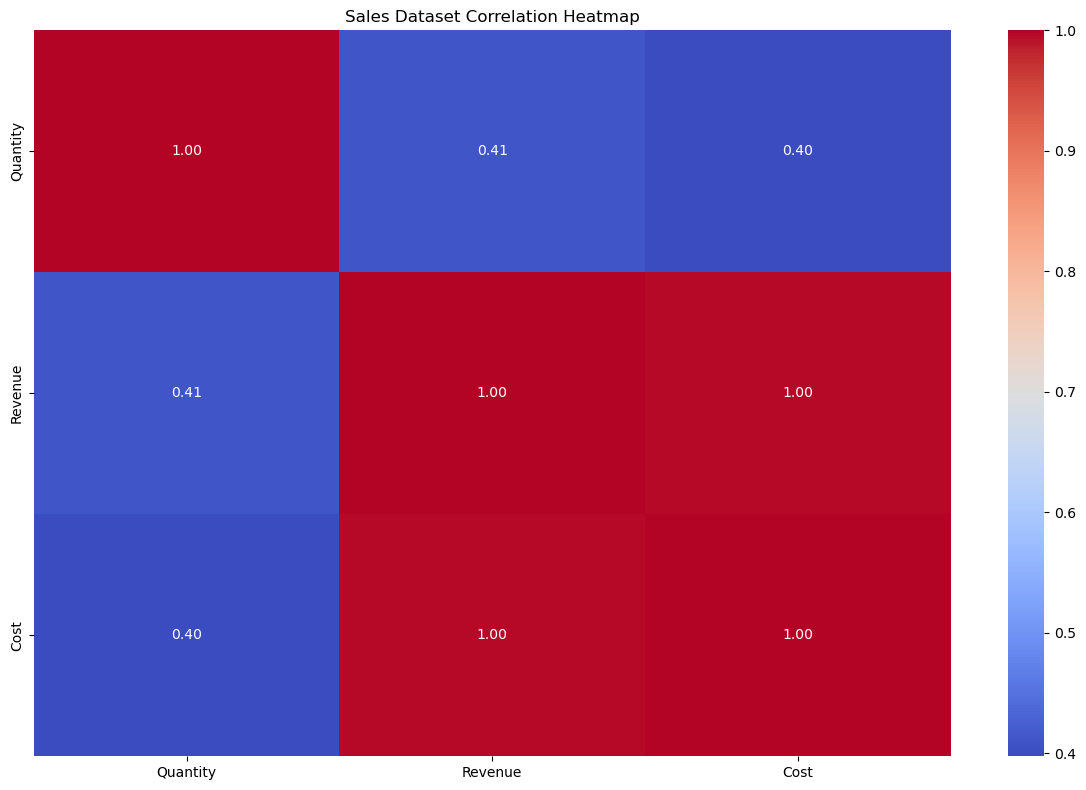

In [17]:
plt.figure(figsize=(12, 8))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Sales Dataset Correlation Heatmap")
plt.tight_layout()

plt.savefig("charts/correlation_heatmap.png")
plt.show()

In [18]:
print(df.columns.tolist())

['Order_ID', 'Order_Date', 'Product_Name', 'Category', 'Region', 'Quantity', 'Revenue', 'Cost', 'Customer_ID']


In [19]:
df.describe(include='all')

,Order_ID,Order_Date,Product_Name,Category,Region,Quantity,Revenue,Cost,Customer_ID
count,1200,1200,1200,1200,1200,1200.000000,1.200000e+03,1.200000e+03,1200
unique,1200,580,60,3,4,NaN,NaN,NaN,450
top,ORD0224,2024-03-21,Van Heusen Shirt,Furniture,South,NaN,NaN,NaN,CUST053
freq,1,7,33,422,352,NaN,NaN,NaN,7
mean,NaN,NaN,NaN,NaN,NaN,3.005000,9.423325e+04,7.047850e+04,NaN
std,NaN,NaN,NaN,NaN,NaN,2.039225,1.622346e+05,1.279418e+05,NaN
min,NaN,NaN,NaN,NaN,NaN,1.000000,1.500000e+03,8.000000e+02,NaN
25%,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000e+04,6.600000e+03,NaN
50%,NaN,NaN,NaN,NaN,NaN,2.000000,3.500000e+04,2.325000e+04,NaN
75%,NaN,NaN,NaN,NaN,NaN,4.000000,1.050000e+05,7.625000e+04,NaN


In [20]:
print(df.head(10))

  Order_ID  Order_Date       Product_Name     Category Region  Quantity  \
0  ORD0224  2024-01-01        Zara Jacket      Fashion   East         9   
1  ORD0210  2024-01-02      Raymond Shirt      Fashion   East         3   
2  ORD0818  2024-01-02      Raymond Shirt      Fashion  North         6   
3  ORD0433  2024-01-02     Forever 21 Top      Fashion  South         2   
4  ORD0391  2024-01-03        Apple Watch  Electronics  South         4   
5  ORD0460  2024-01-03  Sofa Set 5-Seater    Furniture  North         4   
6  ORD1128  2024-01-04      PlayStation 5  Electronics  South         5   
7  ORD1112  2024-01-04  Sofa Set 5-Seater    Furniture  North         1   
8  ORD0805  2024-01-06       Nike T-Shirt      Fashion  South         1   
9  ORD0272  2024-01-07         Zara Dress      Fashion   East         1   

   Revenue    Cost Customer_ID  
0    45000   27000     CUST156  
1     6000    3300     CUST267  
2    12000    6600     CUST315  
3     3000    1600     CUST337  
4   16000

In [21]:
summary = df.describe()

summary

,Quantity,Revenue,Cost
count,1200.000000,1.200000e+03,1.200000e+03
mean,3.005000,9.423325e+04,7.047850e+04
std,2.039225,1.622346e+05,1.279418e+05
min,1.000000,1.500000e+03,8.000000e+02
25%,1.000000,1.000000e+04,6.600000e+03
50%,2.000000,3.500000e+04,2.325000e+04
75%,4.000000,1.050000e+05,7.625000e+04
max,10.000000,2.400000e+06,2.000000e+06


In [22]:
summary_table = df.describe().T

summary_table = summary_table.round(2)

summary_table

,count,mean,std,min,25%,50%,75%,max
Quantity,1200.0,3.00,2.04,1.0,1.0,2.0,4.0,10.0
Revenue,1200.0,94233.25,162234.59,1500.0,10000.0,35000.0,105000.0,2400000.0
Cost,1200.0,70478.50,127941.76,800.0,6600.0,23250.0,76250.0,2000000.0


In [23]:
summary_table.to_csv("summary_statistics.csv")

print("Summary statistics saved successfully!")

Summary statistics saved successfully!
